# Dashboard checks in a browser

**Data source:** the dashboard pages in `../dashboard/` (`index.html`, `detail.html`), built from `build_dashboard.ipynb`.
**Date:** 2026-11-05
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Opens both screens straight from the folder (a `file://` address, with no server and no internet, exactly as the professor will) in a headless Chromium browser, and checks what they show at first load: no errors, no file requested from the internet, every chart drawn as SVG, the KPIs filled in, and the page structure (language, skip links, headings). It also takes screenshots at 1280 × 800 px. Later tasks add the checks of the interactions and of the keyboard.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration](#2.-Initial-exploration)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: checks at first load](#4.-Analysis:-checks-at-first-load)
5. [Accessible visualisation: screenshots](#5.-Accessible-visualisation:-screenshots)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from importlib.metadata import version
from pathlib import Path

import pandas as pd

# Playwright drives a real browser. If it is missing: pip install playwright, then: playwright install chromium
from playwright.async_api import async_playwright

DASHBOARD_DIR = Path('../dashboard').resolve()
OUTPUT_DIR = Path('browser_checks_output')
OUTPUT_DIR.mkdir(exist_ok=True)
SCREEN_SIZE = {'width': 1280, 'height': 800}        # minimum screen of Part 4

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| playwright', version('playwright'))

Python 3.13.18 | pandas 3.0.5 | playwright 1.63.0


## 1. Data loading

The "data" of this notebook are the two pages. Each one is opened with a `file://` address.

In [2]:
# ── The pages and the charts each one must draw ──────────────────────────────
PAGES = {'index.html': ['c1', 'c2', 'c3'], 'detail.html': ['c4', 'c6', 'c7', 'c8', 'c5']}
page_files = pd.DataFrame([(name, (DASHBOARD_DIR / name).exists(), (DASHBOARD_DIR / name).as_uri()) for name in PAGES],
                          columns=['page', 'exists', 'address'])
page_files

,page,exists,address
0,index.html,True,file:///home/claude/cn/Delivery%201/Part%206%2...
1,detail.html,True,file:///home/claude/cn/Delivery%201/Part%206%2...


## 2. Initial exploration

The files the pages load, with their size: the data, the chart specs and the local copies of the libraries.

In [3]:
# ── Files of the dashboard folder ─────────────────────────────────────────────
pd.DataFrame([(str(path.relative_to(DASHBOARD_DIR)), round(path.stat().st_size / 1024, 1))
              for path in sorted(DASHBOARD_DIR.rglob('*')) if path.is_file()], columns=['file', 'KB'])

,file,KB
0,dashboard.css,6.7
1,dashboard.js,6.1
2,data.js,255.1
3,detail.html,7.6
4,index.html,6.1
5,lib/LICENSE-vega-embed.txt,1.5
6,lib/LICENSE-vega-lite.txt,1.5
7,lib/LICENSE-vega.txt,1.5
8,lib/vega-6.2.0.min.js,500.4
9,lib/vega-embed-7.1.0.min.js,58.7


## 3. Cleaning and preparation

Not applicable.

## 4. Analysis: checks at first load

In [4]:
# ── Open each page and collect what it shows ─────────────────────────────────
# Top-level await works in Jupyter; the async API is used because the notebook already runs an event loop.

async def check_page(browser, page_name, charts):
    context = await browser.new_context(viewport=SCREEN_SIZE, device_scale_factor=1)
    page = await context.new_page()
    problems, requests = [], []
    page.on('console', lambda message: problems.append(f'{message.type}: {message.text}')
            if message.type in ('error', 'warning') else None)
    page.on('pageerror', lambda error: problems.append(f'page error: {error}'))
    page.on('request', lambda request: requests.append(request.url))
    await page.goto((DASHBOARD_DIR / page_name).as_uri())
    await page.wait_for_function('names => names.every(n => document.querySelector("#" + n + " svg"))', arg=charts, timeout=20000)
    found = await page.evaluate("""charts => ({
        lang: document.documentElement.lang,
        skip_links: [...document.querySelectorAll('.skip-link')].map(a => a.textContent),
        headings: [...document.querySelectorAll('h1, h2, h3')].map(h => h.tagName + ' ' + h.textContent),
        kpis: [...document.querySelectorAll('.kpi')].map(k => [k.querySelector('dt').textContent,
               k.querySelector('.kpi-value').textContent, k.querySelector('.kpi-context').textContent]),
        showing: document.getElementById('active-filters-text').textContent,
        charts: charts.map(c => {
            const svg = document.querySelector('#' + c + ' svg');
            return {chart: c, svg: !!svg, canvas: !!document.querySelector('#' + c + ' canvas'),
                    marks_with_label: svg ? svg.querySelectorAll('.role-mark [aria-label]').length : 0,
                    heading_as_spec: document.getElementById(c + '-title').textContent === DASHBOARD_SPECS[c].title.text,
                    caption_as_spec: document.getElementById(c + '-description').textContent === DASHBOARD_SPECS[c].description};
        })
    })""", charts)
    await page.screenshot(path=OUTPUT_DIR / page_name.replace('.html', '_1280x800.png'))
    await page.screenshot(path=OUTPUT_DIR / page_name.replace('.html', '_full_page.png'), full_page=True)
    await context.close()
    found.update(page=page_name, problems=problems,
                 internet_requests=[url for url in requests if not url.startswith('file://')],
                 files_loaded=[url.rsplit('/', 1)[-1] for url in requests])
    return found


async with async_playwright() as playwright:
    browser = await playwright.chromium.launch()
    first_load = [await check_page(browser, name, charts) for name, charts in PAGES.items()]
    await browser.close()
print('Pages checked:', [result['page'] for result in first_load])

Pages checked: ['index.html', 'detail.html']


In [5]:
# ── Summary of the checks at first load ──────────────────────────────────────
summary = pd.DataFrame([{
    'page': r['page'],
    'lang="en"': r['lang'] == 'en',
    'errors or warnings': len(r['problems']),
    'files from the internet': len(r['internet_requests']),
    'charts drawn as SVG': sum(c['svg'] and not c['canvas'] for c in r['charts']),
    'charts expected': len(r['charts']),
    'KPIs filled in': sum(value not in ('', '–') for _, value, _ in r['kpis']),
    'skip links': len(r['skip_links']),
    'headings = chart titles': all(c['heading_as_spec'] and c['caption_as_spec'] for c in r['charts']),
} for r in first_load])
print('Everything as expected:', bool((summary['errors or warnings'] == 0).all() and (summary['files from the internet'] == 0).all()
                                      and (summary['charts drawn as SVG'] == summary['charts expected']).all()
                                      and (summary['KPIs filled in'] == 4).all() and summary['headings = chart titles'].all()))
summary

Everything as expected: True


,page,"lang=""en""",errors or warnings,files from the internet,charts drawn as SVG,charts expected,KPIs filled in,skip links,headings = chart titles
0,index.html,True,0,0,3,3,4,2,True
1,detail.html,True,0,0,5,5,4,2,True


In [6]:
# ── What each page shows: KPIs, charts and heading structure ─────────────────
for r in first_load:
    print(f"\n{r['page']} | Showing: {r['showing']} | files loaded: {', '.join(r['files_loaded'][1:])}")
    for label, value, context in r['kpis']:
        print(f'  KPI  {label}: {value} ({context})')
    for c in r['charts']:
        print(f"  {c['chart']}: SVG {c['svg']}, marks with an aria-label: {c['marks_with_label']}")
    print('  Headings:', ' / '.join(r['headings']))


index.html | Showing: Both hotels · All years (July 2015 to August 2017) | files loaded: dashboard.css, data.js, specs.js, vega-6.2.0.min.js, vega-lite-6.4.1.min.js, vega-embed-7.1.0.min.js, dashboard.js
  KPI  Stays: 75,007 (bookings not cancelled, of 119,201)
  KPI  Guests: 145,980 (people in those stays)
  KPI  Bookings cancelled: 37.1 % (of 119,201 bookings; duplicates included (see note))
  KPI  Median price per night: €94.5 (median of stays with a price; euros assumed)
  c1: SVG True, marks with an aria-label: 52
  c2: SVG True, marks with an aria-label: 52
  c3: SVG True, marks with an aria-label: 52
  Headings: H1 Hotel guests in Lisbon and the Algarve / H2 Key figures for the selected filters / H2 Charts / H3 In which months do the city and the resort receive most guests? / H3 In which months are most bookings cancelled? / H3 How does the price per night change through the year? / H2 Filters

detail.html | Showing: Both hotels · All years (July 2015 to August 2017) | files lo

**Finding:** both pages open from the folder with no server and no internet (every file comes from `file://`), with no error or warning in the console, every chart drawn as SVG, the four KPIs filled in for the default filters, `lang="en"`, two skip links and one heading per chart equal to the chart's title.

## 5. Accessible visualisation: screenshots

index.html


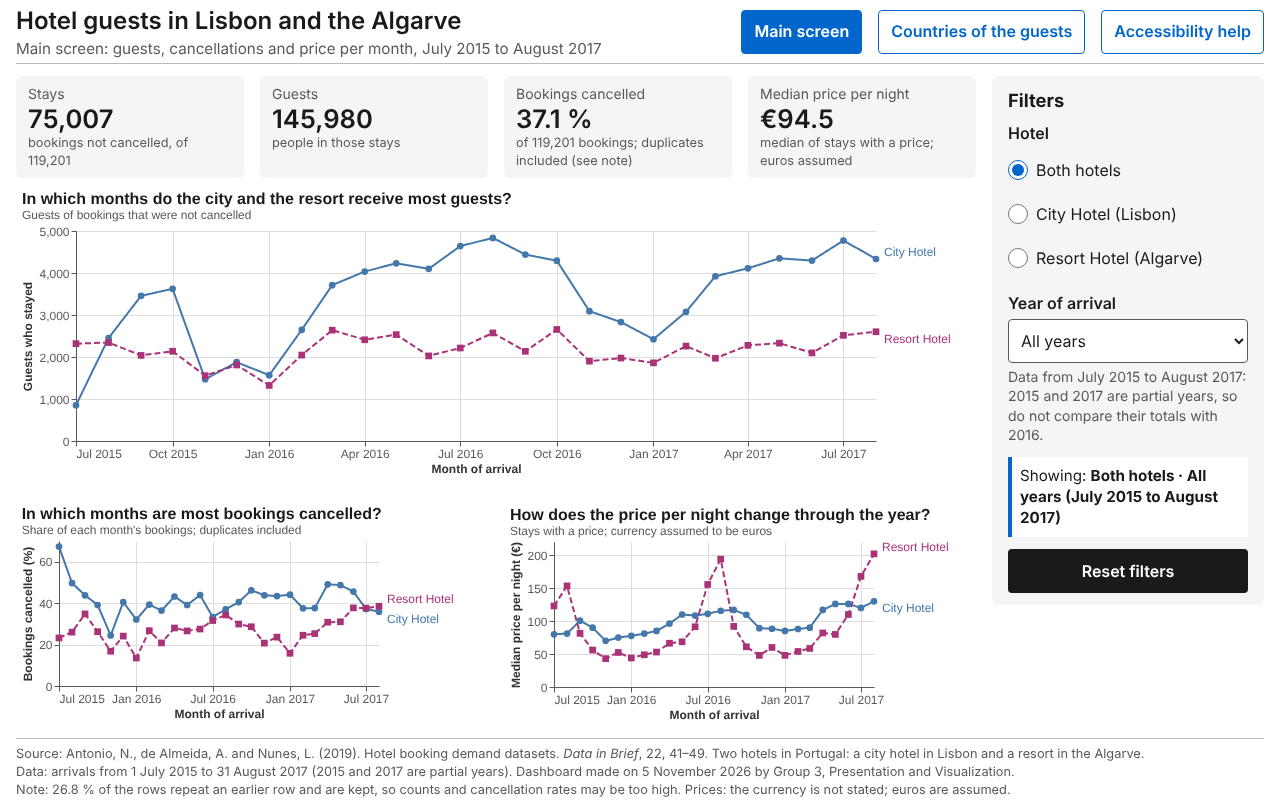

detail.html


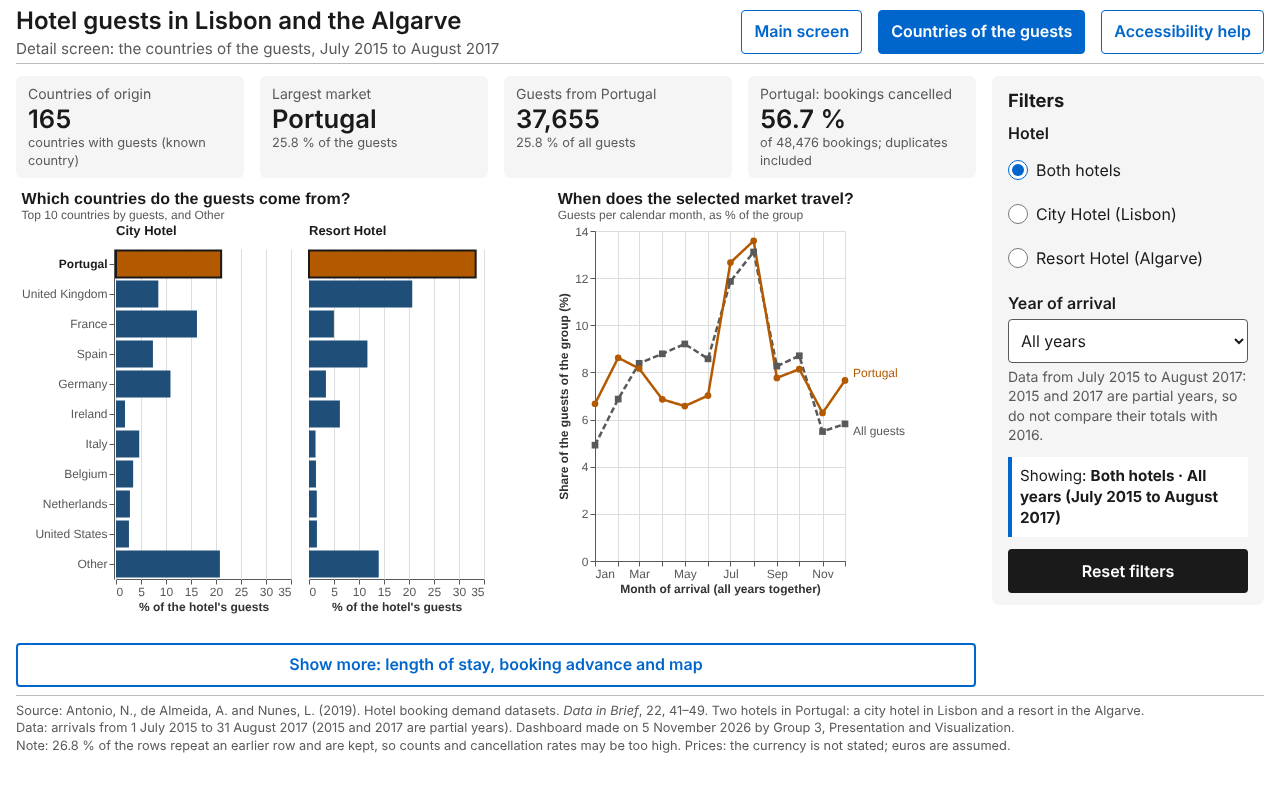

In [7]:
# ── Screenshots at the minimum screen size (1280 x 800 px) ───────────────────
from IPython.display import Image, display
for name in PAGES:
    print(name)
    display(Image(filename=OUTPUT_DIR / name.replace('.html', '_1280x800.png'), width=640))

## 6. Export

In [8]:
# ── Export the results ────────────────────────────────────────────────────────
summary.to_csv(OUTPUT_DIR / 'first_load_checks.csv', index=False)
pd.DataFrame([(r['page'], label, value, context) for r in first_load for label, value, context in r['kpis']],
             columns=['page', 'KPI', 'value', 'context']).to_csv(OUTPUT_DIR / 'first_load_kpis.csv', index=False)
sorted(path.name for path in OUTPUT_DIR.iterdir())

['detail_1280x800.png',
 'detail_full_page.png',
 'first_load_checks.csv',
 'first_load_kpis.csv',
 'index_1280x800.png',
 'index_full_page.png']

## Conclusions

### Task 6.4 (pages)
1. `index.html` and `detail.html` open by double-click, with no server and no internet: the data, the chart specs and the Vega libraries are all local files loaded with `<script src>`.
2. Both show data at first load: four KPIs and every chart, as SVG, with no error in the console.
3. Each page has `lang="en"`, skip links to the charts and the filters, and a heading for each chart.

### Limitations
- Checked in Chromium only (headless); the students should also open the pages in their own browser.
- The filters, the selection of a country and "Show more" are drawn but are made to work in task 6.5; `accessibility.html` is written in task 6.7.

### Next steps
- Task 6.5: the interactions, with checks added to this notebook.